# MOON & MARS TOPOGRAPHY

## Imports

In [1]:
import json
from pathlib import Path
from scipy import ndimage

import numpy as np
import pandas as pd
import rasterio
import requests
import xarray as xr

RAW = Path("../data/raw")
OUT = Path("../data/processed")
FRONT = Path("../public/data")
for d in (RAW / "moon", RAW / "mars", OUT, FRONT):
    d.mkdir(parents=True, exist_ok=True)

PX_PER_CELL = 120                 # 120 px ≈ 55 km on all three DEMs, same as an Earth 0.5° cell
MOON_R = 1_737_400                # m, LOLA reference sphere
MARS_R = 3_396_190                # m, MOLA reference sphere

## Data download (skips files already present)

In [2]:
def download(url, dest):
    dest = Path(dest)
    if dest.exists():
        print(f"✓ already have {dest.name}")
        return dest
    print(f"↓ downloading {dest.name} ...")
    tmp = dest.with_suffix(".part")             # renamed when complete, so an interrupted run is retried
    with requests.get(url, stream=True, timeout=120) as r:
        r.raise_for_status()
        with open(tmp, "wb") as fh:
            for chunk in r.iter_content(chunk_size=1 << 20):
                fh.write(chunk)
    tmp.replace(dest)
    return dest

# Moon: LRO LOLA elevation, 64 px/deg (474 m), principal-axis frame (NASA PGDA, 0.7 GB)
MOON_URL = "https://pgda.gsfc.nasa.gov/data/LOLA_PA/LDEM64_PA_gridline_202405.grd"
moon_path = download(MOON_URL, RAW / "moon" / "LDEM64_PA_gridline_202405.grd")

# Mars: MGS MOLA elevation, 128 px/deg (463 m) (USGS Astrogeology, 2.1 GB)
MARS_URL = "https://planetarymaps.usgs.gov/mosaic/Mars_MGS_MOLA_DEM_mosaic_global_463m.tif"
mars_path = download(MARS_URL, RAW / "mars" / "Mars_MGS_MOLA_DEM_mosaic_global_463m.tif")

✓ already have LDEM64_PA_gridline_202405.grd
✓ already have Mars_MGS_MOLA_DEM_mosaic_global_463m.tif


## Open the elevation models

In [3]:
# Moon: z = km above the 1737.4 km sphere, on a lat/lon grid of nodes (both poles and 0°/360° included)
moon = xr.open_dataset(moon_path)
if moon.lat[0] < moon.lat[-1]:
    moon = moon.isel(lat=slice(None, None, -1))         # north-up, like the GeoTIFFs
moon = moon.isel(lon=slice(0, -1))                      # drop the repeated 360° column
moon_px = 360 / moon.sizes["lon"]
print(f"Moon: {dict(moon.sizes)} | {moon_px * np.pi * MOON_R / 180:.0f} m/px | "
      f"lat {float(moon.lat[0])}..{float(moon.lat[-1])} | lon {float(moon.lon[0])}..{float(moon.lon[-1])}")

# Mars: metres above the areoid, pole-to-pole equirectangular grid starting at 180°W
mars = rasterio.open(mars_path)
mars_lat = 90 - 180 / mars.height * (np.arange(mars.height) + 0.5)
print(f"Mars: {{'lat': {mars.height}, 'lon': {mars.width}}} | {mars.transform.a:.0f} m/px | nodata={mars.nodata} | "
      f"lon {np.degrees(mars.bounds.left / MARS_R):.1f}..{np.degrees(mars.bounds.right / MARS_R):.1f}")

def mars_rows(y0, y1):
    dem = mars.read(1, window=rasterio.windows.Window(0, y0, mars.width, y1 - y0)).astype("float64")
    if mars.nodata is not None:
        dem[dem == mars.nodata] = np.nan
    return dem

# what compute_terrain_features needs per body: rows y0:y1 in metres, latitude of each row, west edge
DEMS = {
    "moon": dict(radius_m=MOON_R, n_cols=moon.sizes["lon"], row_lat=moon.lat.values,
                 lon_left=float(moon.lon[0]) - moon_px / 2,
                 read_rows=lambda y0, y1: moon.z.isel(lat=slice(y0, y1)).values.astype("float64") * 1000),
    "mars": dict(radius_m=MARS_R, n_cols=mars.width, row_lat=mars_lat, lon_left=-180.0,
                 read_rows=mars_rows),
}

Moon: {'lat': 11521, 'lon': 23040} | 474 m/px | lat 90.0..-90.0 | lon 0.0..359.984375
Mars: {'lat': 23040, 'lon': 46080} | 463 m/px | nodata=-32768.0 | lon -180.0..180.0


## Slope, ruggedness, elevation stats per ~55 km cell

In [4]:
### Same method as compute_etopo_features in Cells filtering, on a global lat/lon grid of any body
def compute_terrain_features(read_rows, row_lat, n_cols, lon_left, radius_m, px_per_cell=PX_PER_CELL):
    """Slope (deg), TRI (m), elevation stats per px_per_cell x px_per_cell block.
    Returns one row per cell: cell_id, lat, lon and the same terrain columns as the Earth table.
    """
    px_deg = 360 / n_cols
    dy_m = px_deg * np.pi * radius_m / 180

    kx = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]]) / 8
    ky = np.array([[1, 2, 1], [0, 0, 0], [-1, -2, -1]]) / (8 * dy_m)

    def block_stat(arr, func):
        h, w = arr.shape
        hb, wb = h // px_per_cell, w // px_per_cell
        a = arr[:hb*px_per_cell, :wb*px_per_cell].reshape(hb, px_per_cell, wb, px_per_cell)
        with np.errstate(all="ignore"):
            return func(a, axis=(1, 3))

    def block_percentile(a, q, axis=(1, 3)):
        """Exact np.nanpercentile(a, q, axis) for a 4D (hb, px, wb, px) block array."""
        hb, px1, wb, px2 = a.shape
        flat = a.transpose(0, 2, 1, 3).reshape(hb, wb, px1 * px2)  # (hb, wb, px*px)
        s = np.sort(flat, axis=-1)                                  # NaN sorts to end
        n_valid = np.sum(~np.isnan(flat), axis=-1)                  # (hb, wb)

        idx = (n_valid - 1) * (q / 100.0)                           # linear-interp position
        lo = np.clip(np.floor(idx).astype(int), 0, px1 * px2 - 1)
        hi = np.clip(np.ceil (idx).astype(int), 0, px1 * px2 - 1)
        frac = idx - np.floor(idx)

        v_lo = np.take_along_axis(s, lo[..., None], axis=-1)[..., 0]
        v_hi = np.take_along_axis(s, hi[..., None], axis=-1)[..., 0]
        out = v_lo + frac * (v_hi - v_lo)
        out[n_valid == 0] = np.nan
        return out

    p90 = lambda a, axis: block_percentile(a, 90, axis)
    p10 = lambda a, axis: block_percentile(a, 10, axis)
    nb_y, nb_x = len(row_lat) // px_per_cell, n_cols // px_per_cell
    blocks = {k: np.full((nb_y, nb_x), np.nan) for k in ("slope_mean", "slope_p90", "rough_p10", "elev_min", "elev_max")}

    for b in range(nb_y):                                   # one row of cells at a time
        y0, y1 = b * px_per_cell, (b + 1) * px_per_cell
        r0, r1 = max(y0 - 1, 0), min(y1 + 1, len(row_lat))  # 1-row halo so cell edges see their neighbours
        dem = read_rows(r0, r1)

        dx_m = (dy_m * np.cos(np.radians(row_lat[r0:r1])))[:, None]
        dx_m[dx_m < 1] = np.nan                             # the pole itself has no E-W direction

        dem_f = np.where(np.isnan(dem), np.nanmean(dem), dem)
        dem_f = np.pad(dem_f, ((0, 0), (1, 1)), mode="wrap")            # longitude wraps around the globe
        dzdx = ndimage.convolve(dem_f, kx, mode="nearest")[:, 1:-1] / dx_m
        dzdy = ndimage.convolve(dem_f, ky, mode="nearest")[:, 1:-1]
        slope = np.degrees(np.arctan(np.hypot(dzdx, dzdy)))
        slope[np.isnan(dem)] = np.nan

        tri = np.zeros_like(dem)
        cnt = np.zeros_like(dem)
        for ddy, ddx in [(-1,-1),(-1,0),(-1,1),(0,-1),(0,1),(1,-1),(1,0),(1,1)]:
            nb = np.roll(np.roll(dem, ddy, 0), ddx, 1)
            d = np.abs(dem - nb)
            v = ~np.isnan(d)
            tri[v] += d[v]; cnt[v] += 1
        tri = np.where(cnt > 0, tri / np.maximum(cnt, 1), np.nan)

        keep = slice(y0 - r0, y0 - r0 + px_per_cell)        # drop the halo rows again
        dem, slope, tri = dem[keep], slope[keep], tri[keep]
        blocks["slope_mean"][b] = block_stat(slope, np.nanmean)
        blocks["slope_p90"][b] = block_stat(slope, p90)
        blocks["rough_p10"][b] = block_stat(tri, p10)
        blocks["elev_min"][b] = block_stat(dem, np.nanmin)
        blocks["elev_max"][b] = block_stat(dem, np.nanmax)

    blocks["elev_range"] = blocks["elev_max"] - blocks["elev_min"]

    cell_deg = px_deg * px_per_cell
    lat = row_lat[:nb_y * px_per_cell].reshape(nb_y, px_per_cell).mean(axis=1)
    lon = (lon_left + cell_deg * (np.arange(nb_x) + 0.5) + 180) % 360 - 180
    lon2d, lat2d = np.meshgrid(lon, lat)
    cells = pd.DataFrame({"cell_id": np.arange(nb_y * nb_x), "lat": lat2d.ravel(), "lon": lon2d.ravel()})
    for name, arr in blocks.items():
        cells[name] = arr.ravel()
    return cells

tables = {}
for body, dem in DEMS.items():
    tables[body] = compute_terrain_features(**dem)
    cell_km = 360 / dem["n_cols"] * PX_PER_CELL * np.pi * dem["radius_m"] / 180 / 1000
    print(f"{body}: {len(tables[body]):,} cells of {cell_km:.1f} km ({360 / dem['n_cols'] * PX_PER_CELL:.4f}°)")

moon: 18,432 cells of 56.9 km (1.8750°)


mars: 73,728 cells of 55.6 km (0.9375°)


In [5]:
for body, cells in tables.items():
    print(f"\n{body}:")
    display(cells[["slope_mean", "slope_p90", "rough_p10", "elev_min", "elev_max", "elev_range"]].describe().round(1))


moon:


,slope_mean,slope_p90,rough_p10,elev_min,elev_max,elev_range
count,18432.0,18432.0,18432.0,18432.0,18432.0,18432.0
mean,7.1,14.7,10.3,-2110.3,1052.2,3162.5
std,3.0,5.7,6.2,1826.2,2412.3,1493.6
min,0.2,0.3,0.7,-9123.4,-6016.8,151.2
25%,5.4,11.8,5.2,-3074.4,-490.7,2057.3
50%,7.5,15.5,9.5,-2163.4,776.4,3111.1
75%,9.1,18.5,14.4,-1219.3,2417.1,4127.5
max,18.4,32.1,35.7,6152.7,10774.1,10156.0



mars:


,slope_mean,slope_p90,rough_p10,elev_min,elev_max,elev_range
count,73728.0,73728.0,73728.0,73728.0,73728.0,73728.0
mean,1.7,3.9,1.8,-1173.5,-273.7,899.8
std,1.6,3.9,2.0,2848.4,3099.8,895.0
min,0.0,0.1,0.0,-8201.0,-7200.0,11.0
25%,0.6,1.1,0.8,-3938.0,-3405.2,267.0
50%,1.2,2.5,1.2,-984.0,464.0,648.0
75%,2.3,5.3,2.2,1120.0,2140.0,1247.2
max,20.3,49.6,47.0,18284.0,21241.0,10721.0


## Stable cell ID

In [6]:
def cell_id(body, lat, lon):
    """cell_id of the cell containing (lat, lon), east-positive longitude, for tables[body]."""
    dem = DEMS[body]
    cell_deg = 360 / dem["n_cols"] * PX_PER_CELL
    ncols = dem["n_cols"] // PX_PER_CELL
    lat = np.asarray(lat); lon = np.asarray(lon)
    row = ((90 - lat) // cell_deg).astype(int)                      # 0 = northernmost row
    col = (((lon - dem["lon_left"]) % 360) // cell_deg).astype(int)
    return row * ncols + col

## Reference sites: base candidates and landing sites

In [7]:
sites = pd.DataFrame([
    ("moon", "Shackleton rim (south pole)", -89.7,  129.8),
    ("moon", "Malapert massif",             -86.0,    2.9),
    ("moon", "Apollo 11, Mare Tranquillitatis", 0.67,  23.47),
    ("moon", "Apollo 15, Hadley Rille",     26.13,    3.63),
    ("moon", "Apollo 17, Taurus-Littrow",   20.19,   30.77),
    ("moon", "Marius Hills pit",            14.09,  -56.77),
    ("moon", "Chang'e 4, Von Karman",      -45.44,  177.60),
    ("mars", "Jezero (Perseverance)",       18.44,   77.45),
    ("mars", "Gale (Curiosity)",            -4.59,  137.44),
    ("mars", "Elysium Planitia (InSight)",   4.50,  135.62),
    ("mars", "Meridiani (Opportunity)",     -1.95,   -5.53),
    ("mars", "Gusev (Spirit)",             -14.57,  175.47),
    ("mars", "Utopia Planitia (Zhurong)",   25.07,  109.93),
    ("mars", "Arcadia Planitia",            39.8,  -158.0),
    ("mars", "Vastitas Borealis (Phoenix)", 68.22, -125.75),
], columns=["body", "name", "lat", "lon"])
sites["cell_id"] = [int(cell_id(s.body, s.lat, s.lon)) for s in sites.itertuples()]

cols = ["cell_id", "slope_mean", "slope_p90", "rough_p10", "elev_min", "elev_max", "elev_range"]
sites = pd.concat([sites[sites.body == body].merge(cells[cols], on="cell_id", how="left")
                   for body, cells in tables.items()], ignore_index=True)
print("\nReference sites:")
display(sites.drop(columns="cell_id").round(1))


Reference sites:


,body,name,lat,lon,slope_mean,slope_p90,rough_p10,elev_min,elev_max,elev_range
0,moon,Shackleton rim (south pole),-89.7,129.8,13.1,29.3,10.9,-2784.5,1427.2,4211.7
1,moon,Malapert massif,-86.0,2.9,14.0,24.1,10.5,-2478.2,5169.8,7648.0
2,moon,"Apollo 11, Mare Tranquillitatis",0.7,23.5,0.9,1.5,2.5,-2462.3,-1391.6,1070.8
3,moon,"Apollo 15, Hadley Rille",26.1,3.6,9.0,22.5,2.6,-2957.2,2883.3,5840.5
4,moon,"Apollo 17, Taurus-Littrow",20.2,30.8,9.7,21.0,10.5,-3106.0,-213.1,2892.9
5,moon,Marius Hills pit,14.1,-56.8,1.5,3.2,3.1,-2326.6,-955.3,1371.3
6,moon,"Chang'e 4, Von Karman",-45.4,177.6,0.8,1.4,1.4,-6199.9,-4968.5,1231.4
7,mars,Jezero (Perseverance),18.4,77.4,2.8,6.7,3.2,-3043.0,-1465.0,1578.0
8,mars,Gale (Curiosity),-4.6,137.4,4.8,11.2,5.5,-4600.0,-1582.0,3018.0
9,mars,Elysium Planitia (InSight),4.5,135.6,0.4,0.5,0.5,-3175.0,-2244.0,931.0


## Save tables

In [8]:
for body, cells in tables.items():
    cells.to_parquet(OUT / f"{body}_cells.parquet", index=False)
    print(f"Saved {OUT / f'{body}_cells.parquet'}")
sites.to_parquet(OUT / "planet_sites.parquet", index=False)
print(f"Saved {OUT / 'planet_sites.parquet'}")

Saved ..\data\processed\moon_cells.parquet


Saved ..\data\processed\mars_cells.parquet
Saved ..\data\processed\planet_sites.parquet


## Frontend export

In [9]:
FEATURES = ["slope_p90", "rough_p10", "elev_range"]          # the terrain features cells.json has for Earth

for body, cells in tables.items():
    front = {"cell_id": cells.cell_id.tolist(),
             "lat": cells.lat.round(2).tolist(),
             "lon": cells.lon.round(2).tolist()}
    for f in FEATURES:
        front[f] = cells[f].round(3).tolist()
    with open(FRONT / f"{body}_cells.json", "w") as fh:
        json.dump(front, fh, separators=(",", ":"), allow_nan=False)
    print(f"Exported {body}_cells.json ({len(cells):,} cells)")

with open(FRONT / "planet_sites.json", "w") as fh:
    json.dump(sites.round(3).to_dict("records"), fh, separators=(",", ":"), allow_nan=False)
print(f"Exported planet_sites.json ({len(sites)} sites)")

Exported moon_cells.json (18,432 cells)


Exported mars_cells.json (73,728 cells)
Exported planet_sites.json (15 sites)


# Visual

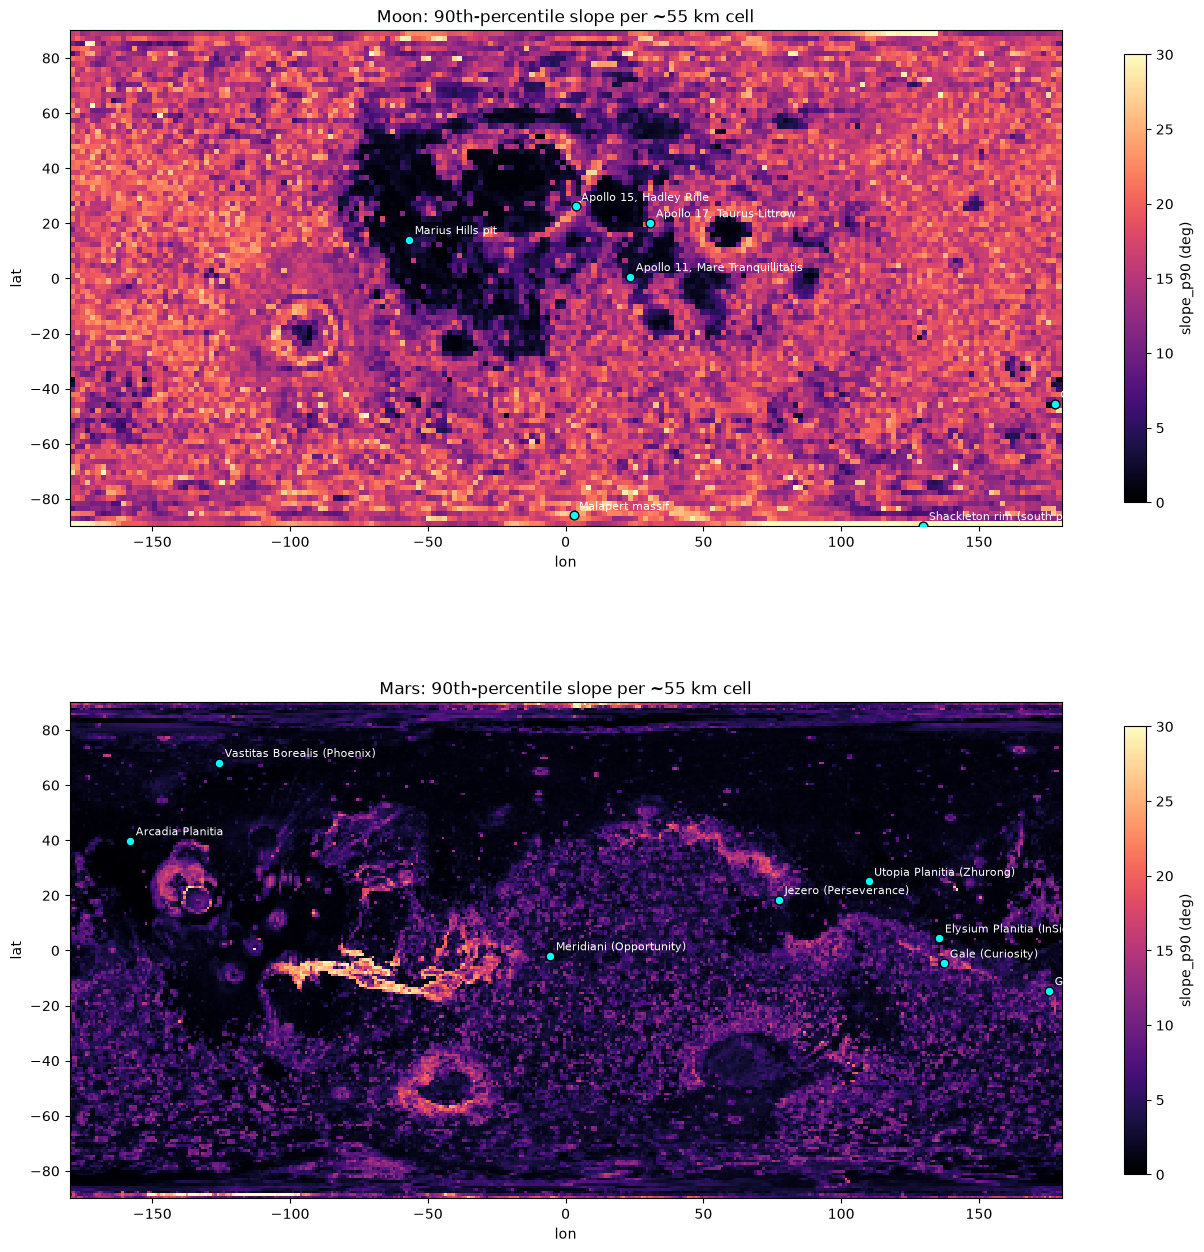

In [10]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 1, figsize=(16, 16))
for ax, (body, cells) in zip(axes, tables.items()):
    ncols = DEMS[body]["n_cols"] // PX_PER_CELL
    grid = cells.sort_values("cell_id").slope_p90.values.reshape(-1, ncols)
    grid = np.roll(grid, round((DEMS[body]["lon_left"] + 180) / 360 * ncols), axis=1)       # start the map at 180°W
    im = ax.imshow(grid, extent=[-180, 180, -90, 90], cmap="magma", vmin=0, vmax=30, interpolation="nearest")
    s = sites[sites.body == body]
    ax.scatter(s.lon, s.lat, c="cyan", s=40, edgecolor="k", zorder=3)
    for a in s.itertuples():
        ax.annotate(a.name, (a.lon, a.lat), xytext=(4, 4), textcoords="offset points", fontsize=8, color="white")
    fig.colorbar(im, ax=ax, label="slope_p90 (deg)", shrink=0.8)
    ax.set_title(f"{body.capitalize()}: 90th-percentile slope per ~55 km cell")
    ax.set_xlabel("lon"); ax.set_ylabel("lat")
plt.show()